# PRT (Bus) Stops
For college students and city-dwellers in general, public transport is THE way to get around. According to the United States Census Bureau, every year over 10% of Pittsburgh residents commute using the Public Regional Transport System, and that's not even counting how many people commute from outside of Pittsburgh. 

I'll be focusing on internal public transport, specifically buses, for my submetric. <br>
Going off of the above, it makes sense for a good neighborhood in Pittsburgh to have abundant bus stops. In this analysis I will be excluding the incline and the light rail because "who decides where to live based on whether or not it has an incline within walking distance??" <br>

[talk more technical detai lhere]# PRT (Bus) Stops
For college students and city-dwellers in general, public transport is THE way to get around. According to the United States Census Bureau, every year over 10% of Pittsburgh residents commute using the Public Regional Transport System, and that's not even counting how many people commute from outside of Pittsburgh. 

I'll be focusing on internal public transport, specifically buses, for my submetric. <br>
Going off of the above, it makes sense for a good neighborhood in Pittsburgh to have abundant bus stops. In this analysis I will be excluding the incline and the light rail because "who decides where to live based on whether or not it has an incline within walking distance??" <br>

We'll use the PRT type and neighborhood columns to sort and analyze the data.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Import my chosen csv
# %cd /ihome/cmpinf0010-sec1010_2026f/lyy7/Lyakovlev Submetric
stops = pd.read_csv("Transit_Stops.csv")import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Import my chosen csv
PRT_stops = pd.read_csv("Transit_Stops.csv")

# Show the new dataset assignment was successful
bus_stops = PRT_stops[(PRT_stops["mode"] == "BUS") & (PRT_stops["muni"] == "Pittsburgh city (Allegheny, PA)")][["mode", "hood"]]
bus_stops.head()

,mode,hood
0,BUS,Strip District
1,BUS,Polish Hill
2,BUS,Strip District
3,BUS,Lower Lawrenceville
4,BUS,Central Lawrenceville


I have created a new dataframe from the original that uses two query masks: one that limits the rows to bus stops, and one that limits those rows to Pittsburgh city stops, since I noticed the frame also includes nearby counties.<br>

Now, it's time to start breaking it down!

In [4]:
# Use a dictionary to count how many times each neighborhood appears
dic = {}
for index, row in bus_stops.iterrows():
    neighborhood = row["hood"]

    if neighborhood not in dic:
        dic[neighborhood] = 1
    else:
        dic[neighborhood] += 1
        
# Sort in descending order based on stop count
# Sorted method automatically does this, but we have to use a one-line function to look at the number assigned to each key
dic = dict(sorted(dic.items(), key=lambda item: item[1]))

for neighborhood in dic:
    print(neighborhood, ":" , dic[neighborhood], "stops")

Ridgemont : 2 stops
Swisshelm Park : 3 stops
St. Clair : 3 stops
New Homestead : 4 stops
East Carnegie : 4 stops
North Shore : 6 stops
Chartiers City : 6 stops
Hays : 7 stops
Arlington-Arlington Heights : 8 stops
Central Oakland : 9 stops
Fairywood : 9 stops
Oakwood : 9 stops
Esplen : 9 stops
Regent Square : 10 stops
Fineview : 10 stops
Mt. Oliver : 10 stops
Allegheny West : 11 stops
Bedford Dwellings : 11 stops
Bon Air : 11 stops
South Shore : 11 stops
Duquesne Heights : 12 stops
Overbrook : 13 stops
West End : 13 stops
Banksville : 13 stops
Beechview : 15 stops
Friendship : 16 stops
Glen Hazel : 16 stops
California-Kirkbride : 16 stops
Central Northside : 16 stops
Point Breeze North : 17 stops
South Oakland : 17 stops
Chateau : 19 stops
Allentown : 19 stops
Windgap : 19 stops
Homewood West : 21 stops
Elliott : 21 stops
Westwood : 21 stops
Upper Hill : 22 stops
Northview Heights : 22 stops
Bluff : 23 stops
Summer Hill : 23 stops
Strip District : 24 stops
Highland Park : 24 stops
Stant

Okay, that's a bit long. 90 neighborhoods is nothing to sneeze at! <br>
Let's graph this out. I'm only doing the top 20 neighborhoods because all 90 would not be readable at all.

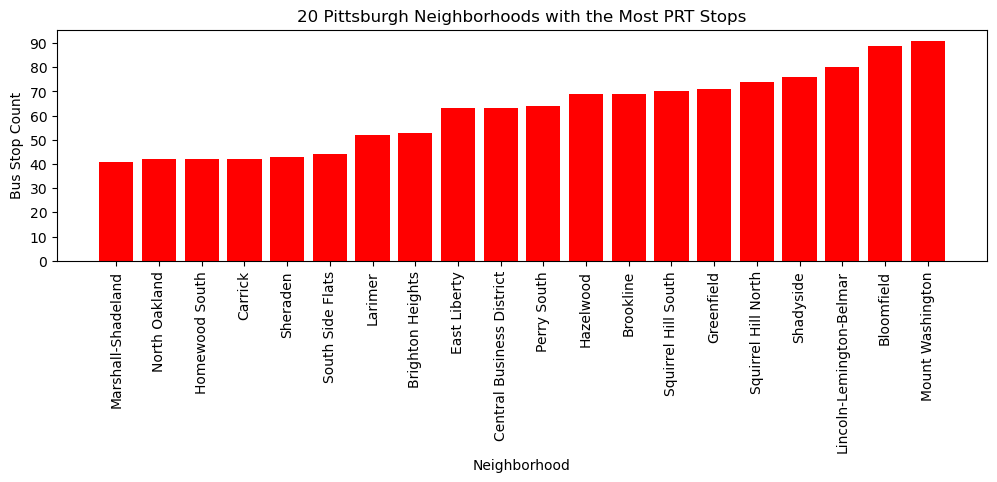

In [5]:
# Use matplotlib keys and values to plot a bar graph of the dictionary
# Replace() used to format neighborhood names such that they don't overlap
neighborhoods = list(dic.keys())[-20:]
stops = list(dic.values())[-20:]

plt.figure(figsize=(12, 3))
plt.bar(neighborhoods, stops, color = "red")
plt.title("20 Pittsburgh Neighborhoods with the Most PRT Stops")
plt.xlabel("Neighborhood")
plt.ylabel("Bus Stop Count")

# Use numpy just to help with formatting
plt.xticks(rotation=90)
plt.yticks(np.arange(0, 100, 10))

plt.show()

Going solely off of the number of bus stops, <b> Mount Washington </b> would be the best neighborhood!

This isn't perfect, though. Is just the number of bus stops in a neighborhood enough to determine if it's convenient to live there? One neighborhood may have 10 versus another with 1, but chances are that first neighborhood is far larger than the second. 

We can take this a step further by looking at neighborhood PRT Bus Stops <b>by square mile.</b>

# PRT Bus Stops Per Square Mile

We'll need to bring in a new dataframe for these calculations. Don't worry, it's a simple one: City of Pittsburgh GIS Data HUB's <b> "Neighborhoods"</b> dataframe. <br>
Luckily, we only need to grab the neighborhood and square mileage columns.

In [16]:
areas = pd.read_csv("Neighborhoods_.csv")[["hood","sqmiles"]]
areas.head()

,hood,sqmiles
0,Point Breeze North,0.301921
1,Squirrel Hill North,1.223409
2,Garfield,0.457385
3,Bedford Dwellings,0.175674
4,Knoxville,0.299625


Now, we can find a more accurate ranking by dividing each neighborhood by its square mileage. We'll do this by dividing the square mileage value for each neighborhood in the dataframe by the matching bus stop dictionary value (the bus stop count). These calculations will be stored in a new dictionary.

In [60]:
ratios = {}
# Bring each neighborhood into the dictionary from the dataframe
# I would reuse the bus stops dictionary above but I think it's more understandable to make a new one
for index, row in bus_stops.iterrows():
    neighborhood = row["hood"]
    
    if neighborhood not in ratios:
        ratios[neighborhood] = 1
    else:
        ratios[neighborhood] += 1

# Get each ratio
# Conveniently, each row/neighborhood only appears once in the areas dataframe, so we don't need to worry about accidentally dividing twice
for index, row in areas.iterrows():
    # Make sure to check each value in dictionary
    for neighborhood in ratios:
        # If they match, divide the stop count by square mileage to find stops per sq. mile
        if neighborhood == row["hood"]:
            ratios[neighborhood] = ratios[neighborhood]/row["sqmiles"]

# Before printing the dictionary, sort in ascending order (copied code from above)
# Only return the last 20
ratios = dict(sorted(ratios.items(), key=lambda item: item[1])[-20:])

# We will also round to the nearest whole bus stop for ease of understanding
for ratio in ratios:
    print(ratio, ":", round(ratios[ratio]), "stops per square mile")

Beltzhoover : 89 stops per square mile
Greenfield : 92 stops per square mile
Manchester : 93 stops per square mile
Morningside : 96 stops per square mile
Knoxville : 97 stops per square mile
Mt. Oliver : 97 stops per square mile
Spring Garden : 97 stops per square mile
Central Business District : 98 stops per square mile
Polish Hill : 105 stops per square mile
Homewood West : 108 stops per square mile
Terrace Village : 108 stops per square mile
East Liberty : 108 stops per square mile
Homewood South : 108 stops per square mile
Larimer : 117 stops per square mile
East Allegheny : 119 stops per square mile
Allegheny Center : 124 stops per square mile
Bloomfield : 127 stops per square mile
West Oakland : 137 stops per square mile
Friendship : 151 stops per square mile
Crawford-Roberts : 163 stops per square mile


Notice how Crawford-Roberts has 163 stops? It sounds wrong, but this just means that if Crawford-Roberts were to be one mile in size, it'd have that many stops. In other words, compared to all the other neighborhoods, it has the most bus stops for its size (41 stops for 0.251 square miles).

Is this extrapolation completely accurate? No, because realistically, a neighborhood of any size could have any number of stops, but it's definitely fun to think about. 

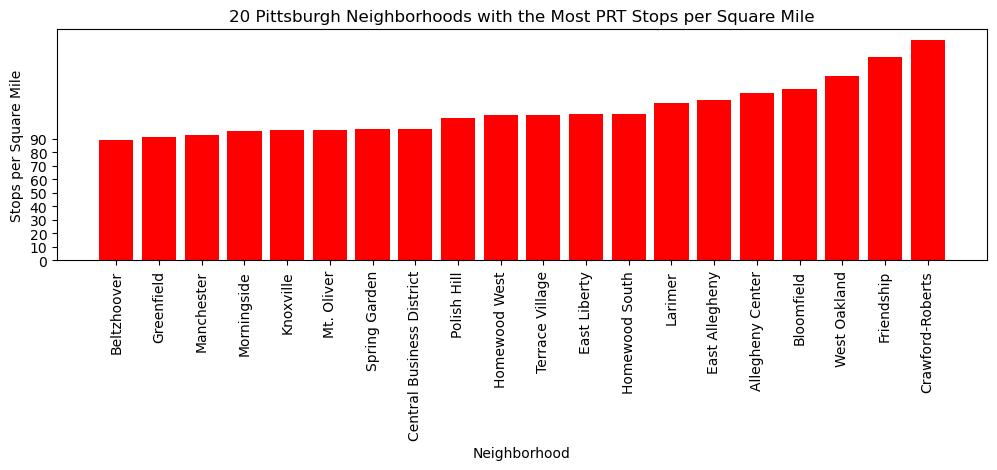

In [62]:
# Copy plotting code from above
neighborhoods = list(ratios.keys())[-20:]
ratio = list(ratios.values())[-20:]

plt.figure(figsize=(12, 3))
plt.bar(neighborhoods, ratio, color = "red")
plt.title("20 Pittsburgh Neighborhoods with the Most PRT Stops per Square Mile")
plt.xlabel("Neighborhood")
plt.ylabel("Stops per Square Mile")

# Use numpy just to help with formatting
plt.xticks(rotation=90)
plt.yticks(np.arange(0, 100, 10))

plt.show()

So, going off of this metric, <b> Crawford-Roberts </b> has the "best" PRT stop density, ensuring for easy travel and minimal movement if you miss a stop!

# Conclusion
So, after many calculations, it was determined that Mount Washington is the best neighborhood based on bus stop count, and Crawford-Roberts is the best neighborhood by the ratio of bus stops to square mileage. If I had to pick one, though, I'd go with <b> Crawford-Roberts </b> as the best neighborhood overall because 91 stops is less meaningful in a 1.1-square-mile-neighborhood than 41 of them in a miniscule 0.251-square-mile one. That being said, Mount Washington's statistics are nothing to sneeze at; it has ~81 stops per square mile. It doesn't beat Crawford-Roberts though. I haven't been to either of these neighborhoods, but I'm not surprised Crawford-Roberts came out on top considering geographically it's in the densest part of Pittsburgh City (right next to downtown), whereas Mount Washington is across the river (while still close to the center).

There are certain metrics that would make people cautious about moving to Crawford-Roberts, but if you're JUST looking for a place with crazy bus stop density, this is the neighborhood for you!